<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week2_Miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
from google.colab import files
files.upload()

Saving US Superstore data.xls to US Superstore data.xls


{'US Superstore data.xls': b'\xd0\xcf\x11\xe0\xa1\xb1\x1a\xe1\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00>\x00\x03\x00\xfe\xff\t\x00\x06\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x004\x00\x00\x00\x01\x00\x00\x00\x00\x00\x00\x00\x00\x10\x00\x00s\x19\x00\x00\x01\x00\x00\x00\xfe\xff\xff\xff\x00\x00\x00\x00\x00\x00\x00\x00b\x00\x00\x00\xe3\x00\x00\x00d\x01\x00\x00\xe5\x01\x00\x00f\x02\x00\x00\xe7\x02\x00\x00h\x03\x00\x00\xe9\x03\x00\x00j\x04\x00\x00\xeb\x04\x00\x00l\x05\x00\x00\xed\x05\x00\x00n\x06\x00\x00\xef\x06\x00\x00p\x07\x00\x00\xf1\x07\x00\x00r\x08\x00\x00\xf3\x08\x00\x00t\t\x00\x00\xf5\t\x00\x00v\n\x00\x00\xf7\n\x00\x00x\x0b\x00\x00\xf9\x0b\x00\x00z\x0c\x00\x00\xfb\x0c\x00\x00|\r\x00\x00\xfd\r\x00\x00~\x0e\x00\x00\xff\x0e\x00\x00\x80\x0f\x00\x00\xe1\x0f\x00\x00b\x10\x00\x00\xe3\x10\x00\x00d\x11\x00\x00\xe5\x11\x00\x00f\x12\x00\x00\xe7\x12\x00\x00h\x13\x00\x00\xe9\x13\x00\x00j\x14\x00\x00\xeb\x14\x00\x00l\x15\x00\x00\xed\x15\x00\x00n\x16\x00\x00\xef\x16\x00\x00p\x1

In [49]:
!pip install xlrd

In [5]:
import pandas as pd

xls_path = '/content/US Superstore data.xls'

df = pd.read_excel(xls_path, engine='xlrd')

csv_path = '/content/US_Superstore_data.csv'
df.to_csv(csv_path, index=False)
print(f"Successfully converted and saved as: {csv_path}")

display(df.head())


Successfully converted and saved as: /content/US_Superstore_data.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


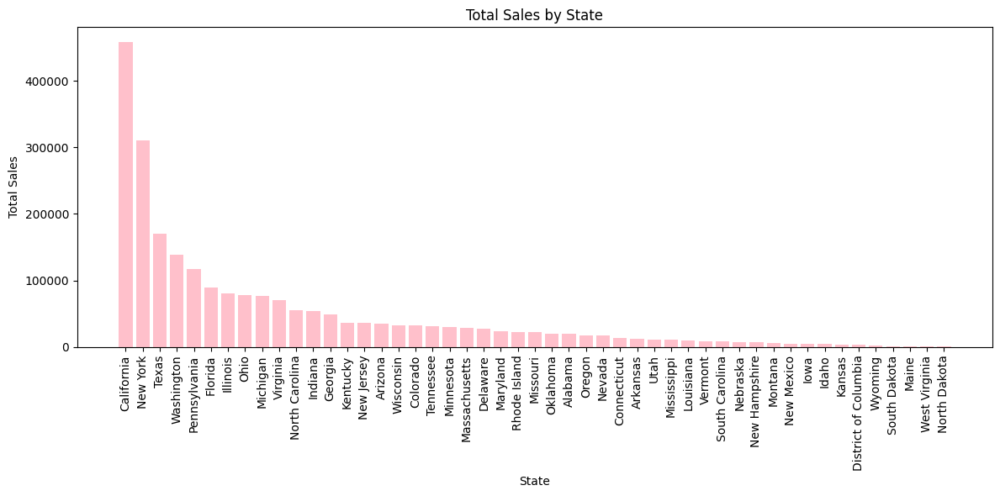

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

state_sales = df.groupby('State')['Sales'].sum().reset_index()
state_sales = state_sales.sort_values(by='Sales', ascending=False, ignore_index=True)
plt.figure(figsize=(12, 6))
plt.bar(state_sales['State'], state_sales['Sales'], color = 'pink')
plt.xlabel('State')
plt.ylabel('Total Sales')
plt.title('Total Sales by State')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


,Sales,Profit
State,,
California,457687.6315,76381.3871
New York,310876.2710,74038.5486


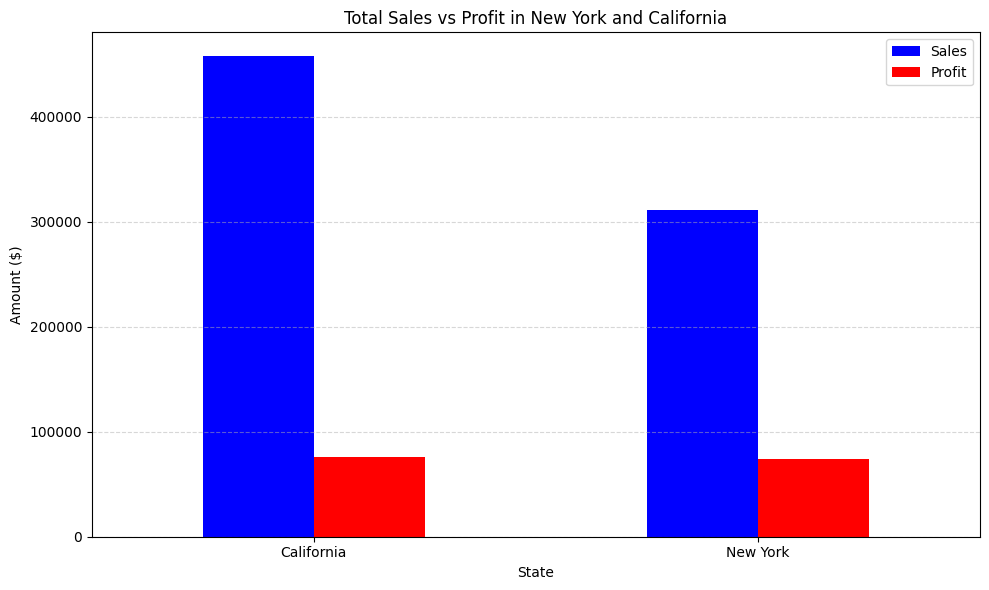

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

filtered_df = df[df['State'].isin(['California', 'New York'])]

states_sales_profit = filtered_df.groupby('State')[['Sales', 'Profit']].sum()

display(states_sales_profit)

ax = states_sales_profit.plot(kind='bar', figsize=(10, 6), color=['blue', 'red'])

plt.xlabel('State')
plt.ylabel('Amount ($)')
plt.title('Total Sales vs Profit in New York and California')
plt.xticks(rotation=0)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.legend(['Sales', 'Profit'])
plt.tight_layout()
plt.show()

In [23]:
import pandas as pd

filtered_state = df[df['State'].isin([ 'New York'])]
customer_sales = filtered_state.groupby('Customer Name')['Sales'].sum().reset_index()
customer_sales = customer_sales.sort_values(by='Sales', ascending=False, ignore_index=True)
display(customer_sales)

,Customer Name,Sales
0,Tom Ashbrook,13723.498
1,Peter Fuller,7678.228
2,Seth Vernon,7359.918
3,Tom Boeckenhauer,6999.960
4,Greg Tran,6712.744
...,...,...
410,Anthony Johnson,4.992
411,Quincy Jones,4.950
412,Henry MacAllister,4.616
413,Jasper Cacioppo,3.928


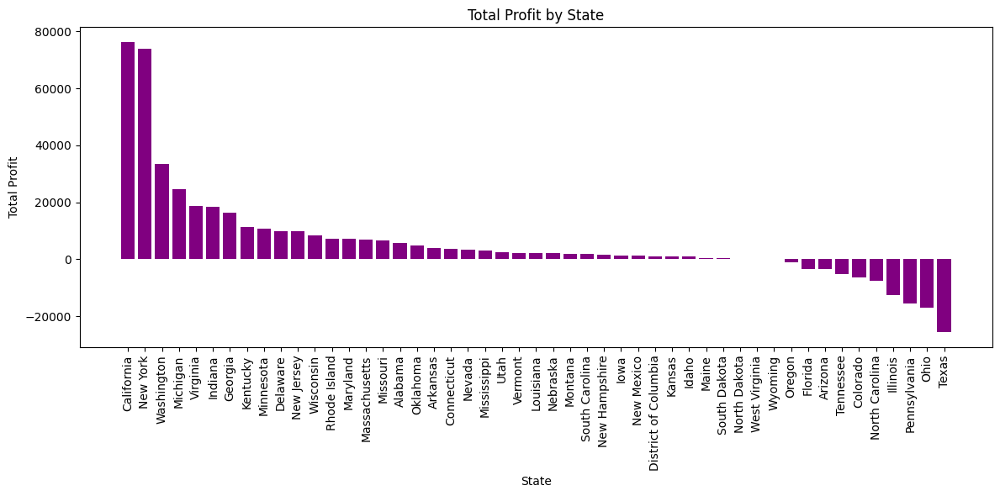

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

state_profit = df.groupby('State')['Profit'].sum().reset_index()
state_profit = state_profit.sort_values(by='Profit', ascending=False, ignore_index=True)
plt.figure(figsize=(12, 6))
plt.bar(state_profit['State'], state_profit['Profit'], color = 'purple')
plt.xlabel('State')
plt.ylabel('Total Profit')
plt.title('Total Profit by State')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customer_profit = df.groupby('Customer Name')['Profit'].sum().reset_index()
customer_profit = customer_profit.sort_values(by='Profit', ascending=False, ignore_index=True)

total_customer = len(customer_profit)
top_20_customers = int(total_customer * 0.2)

# Sum only the 'Profit' column to prevent summing string names
top_20_profit_sum = customer_profit.head(top_20_customers)['Profit'].sum()
total_profit_sum = customer_profit['Profit'].sum()

share = (top_20_profit_sum / total_profit_sum) * 100
print(f"Top 20% of customers ({top_20_customers}) generate {share:.1f}% of profit")

Top 20% of customers (158) generate 81.4% of profit


In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

top_20cities_sales = df.groupby('City')['Sales'].sum().reset_index()
top_20cities_sales = top_20cities_sales.sort_values(by='Sales', ascending=False, ignore_index=True)
top_20cities_sales = top_20cities_sales.head(20)


top_20cities_profit = df.groupby('City')['Profit'].sum().reset_index()
top_20cities_profit = top_20cities_profit.sort_values(by='Profit', ascending=False, ignore_index=True)
top_20cities_profit = top_20cities_profit.head(20)

display(top_20cities_sales)
display(top_20cities_profit)




,City,Sales
0,New York City,256368.1610
1,Los Angeles,175851.3410
2,Seattle,119540.7420
3,San Francisco,112669.0920
4,Philadelphia,109077.0130
5,Houston,64504.7604
6,Chicago,48539.5410
7,San Diego,47521.0290
8,Jacksonville,44713.1830
9,Springfield,43054.3420


,City,Profit
0,New York City,62036.9837
1,Los Angeles,30440.7579
2,Seattle,29156.0967
3,San Francisco,17507.3854
4,Detroit,13181.7908
5,Lafayette,10018.3876
6,Jackson,7581.6828
7,Atlanta,6993.6629
8,Minneapolis,6824.5846
9,San Diego,6377.1960


/tmp/ipykernel_943/1009494259.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_943/1009494259.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


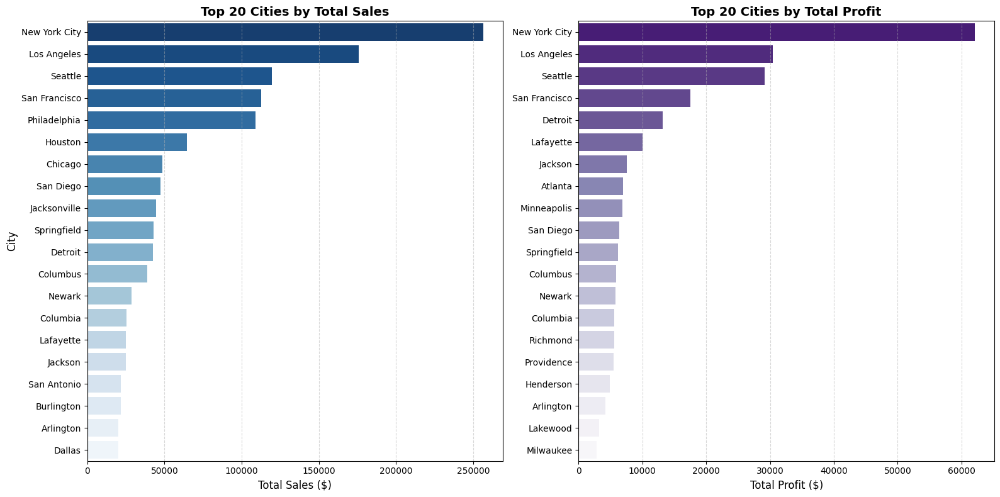

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(
    x='Sales',
    y='City',
    data=top_20cities_sales,
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Top 20 Cities by Total Sales', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Sales ($)', fontsize=12)
axes[0].set_ylabel('City', fontsize=12)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Plot 2: Top 20 Cities by Profit
sns.barplot(
    x='Profit',
    y='City',
    data=top_20cities_profit,
    ax=axes[1],
    palette='Purples_r'
)
axes[1].set_title('Top 20 Cities by Total Profit', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Profit ($)', fontsize=12)
axes[1].set_ylabel('', fontsize=12) # Remove y-label for the second plot since city names are there
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

top_customer = df.groupby('Customer Name')['Sales'].sum().reset_index()
top_customer = top_customer.sort_values(by='Sales', ascending=False, ignore_index=True)
top_customer = top_customer.head(20)

display(top_customer)

,Customer Name,Sales
0,Sean Miller,25043.050
1,Tamara Chand,19052.218
2,Raymond Buch,15117.339
3,Tom Ashbrook,14595.620
4,Adrian Barton,14473.571
5,Ken Lonsdale,14175.229
6,Sanjit Chand,14142.334
7,Hunter Lopez,12873.298
8,Sanjit Engle,12209.438
9,Christopher Conant,12129.072


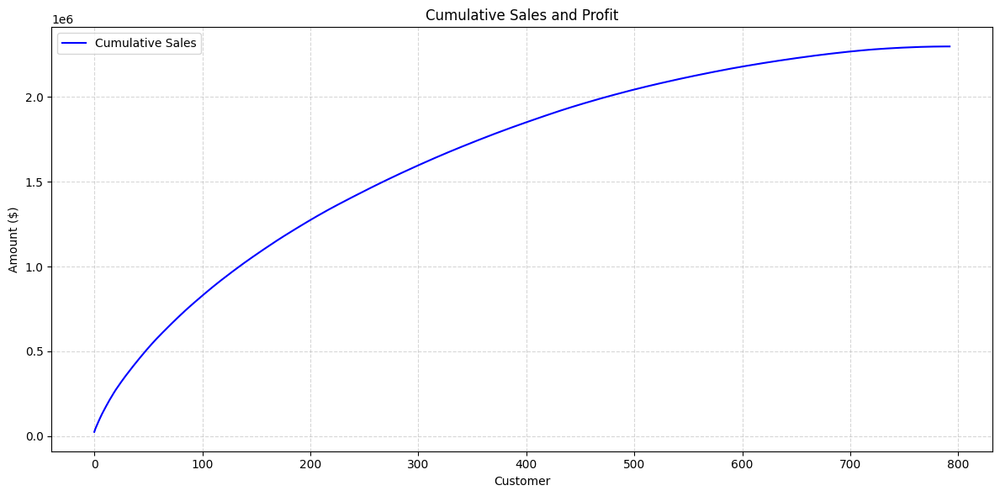

In [46]:
#cumulative curve

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

total_customer = df.groupby('Customer Name')['Sales'].sum().reset_index()
total_customer = total_customer.sort_values(by='Sales', ascending=False, ignore_index=True)
cumulative_customer_sales = total_customer['Sales'].cumsum()

plt.figure(figsize=(12, 6))
plt.plot(cumulative_customer_sales, label='Cumulative Sales', color='blue')
plt.xlabel('Customer')
plt.ylabel('Amount ($)')
plt.title('Cumulative Sales and Profit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Pareto Check:
Total Customers: 793
Top 20% of Customers (158) account for 47.96% of total Sales.



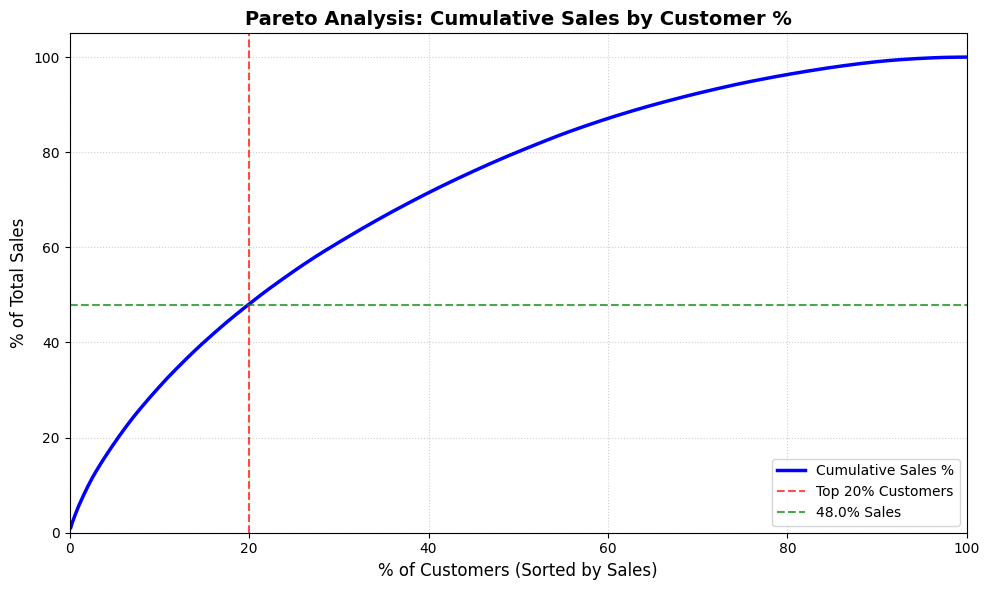

In [47]:
import numpy as np

customer_sales = df.groupby('Customer Name')['Sales'].sum().reset_index()
customer_sales = customer_sales.sort_values(by='Sales', ascending=False, ignore_index=True)

total_sales = customer_sales['Sales'].sum()
customer_sales['Cumulative_Sales_Pct'] = customer_sales['Sales'].cumsum() / total_sales * 100

total_customers_count = len(customer_sales)
customer_sales['Customer_Percentile'] = (customer_sales.index + 1) / total_customers_count * 100

top_20_count = int(total_customers_count * 0.2)
top_20_sales_share = customer_sales.loc[top_20_count - 1, 'Cumulative_Sales_Pct']

print(f"Pareto Check:")
print(f"Total Customers: {total_customers_count}")
print(f"Top 20% of Customers ({top_20_count}) account for {top_20_sales_share:.2f}% of total Sales.\n")

# 4. Plotting the normalized cumulative curve (Lorenz Curve style)
plt.figure(figsize=(10, 6))
plt.plot(customer_sales['Customer_Percentile'], customer_sales['Cumulative_Sales_Pct'], color='blue', lw=2.5, label='Cumulative Sales %')

# Mark the 20% / 80% intersection
plt.axvline(x=20, color='red', linestyle='--', alpha=0.7, label='Top 20% Customers')
plt.axhline(y=top_20_sales_share, color='green', linestyle='--', alpha=0.7, label=f'{top_20_sales_share:.1f}% Sales')

plt.title('Pareto Analysis: Cumulative Sales by Customer %', fontsize=14, fontweight='bold')
plt.xlabel('% of Customers (Sorted by Sales)', fontsize=12)
plt.ylabel('% of Total Sales', fontsize=12)
plt.xlim(0, 100)
plt.ylim(0, 105)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Based on the analysis, both california and new york has the highest sales and also profitability is is high. Would definitely prioritize in these states. On the other hands states like Texas, Ohio, Pennsylvania, iilinois, North Carolina,colarado, Tennesse, Arizona, Florida Oregon, the profit is negative. It is worth looking into what's going on here, customer sales, products, discounts. I will further analyze here to see why the profit is negative. One more interesting thing to notice is top 20% of customer overall generate 80% of profit which is also something to look into further.

 The 80/20 Rule Check:
* Profits are heavily concentrated:  Only **20% of your customers make up over 81% of your profits**. This means a small group of VIPs are keeping the lights on. They need high-touch support or loyalty programs.
* **Sales are much more spread out:** Interestingly, that same top 20% of customers only generate **48% of total sales**. This tells us that many of your lower-profit customers are buying high volumes of cheap or heavily discounted items.

#### 2. Why are Texas, Ohio, PA, and Illinois losing money?
* **Discounting is likely out of control:** Look at the average discounts in these states. If salespeople are giving away 50-70% off to hit sales targets, it completely kills the profit margins.
* **Shipping costs:** These states cover huge geographic areas. Check if high freight/shipping costs are eating up the margins on bulky items.

#### 3. What to do next:
* **Keep California and New York happy:** Since they are your goldmines, double down on marketing and keep inventory stocked there.
* **Fix the bleeders, don't run away:** Instead of stopping sales in places like Texas, try capping maximum discounts at 15-20% and set a minimum order size for free shipping to see if they turn profitable.

In [48]:
# Let's investigate the bleeding states: Texas, Ohio, Pennsylvania, Illinois
loss_states = ['Texas', 'Ohio', 'Pennsylvania', 'Illinois']
profit_states = ['California', 'New York']

# Calculate average discount and profit margin in loss states vs profit states
print("=== Discount & Profit Margin Comparison ===")
for group_name, states in [("Bleeding States (TX, OH, PA, IL)", loss_states), ("Profitable States (CA, NY)", profit_states)]:
    sub_df = df[df['State'].isin(states)]
    avg_discount = sub_df['Discount'].mean() * 100
    total_sales = sub_df['Sales'].sum()
    total_profit = sub_df['Profit'].sum()
    margin = (total_profit / total_sales) * 100
    print(f"{group_name}:")
    print(f"  Average Discount: {avg_discount:.1f}%")
    print(f"  Profit Margin: {margin:.1f}%")

print("\n=== Top Loss-Making Sub-Categories in Bleeding States ===")
loss_subcats = df[df['State'].isin(loss_states)].groupby('Sub-Category')[['Sales', 'Profit', 'Discount']].agg({'Sales':'sum', 'Profit':'sum', 'Discount':'mean'}).reset_index()
loss_subcats['Discount %'] = loss_subcats['Discount'] * 100
loss_subcats = loss_subcats.sort_values(by='Profit').head(5)
display(loss_subcats)

=== Discount & Profit Margin Comparison ===
Bleeding States (TX, OH, PA, IL):
  Average Discount: 35.6%
  Profit Margin: -15.9%
Profitable States (CA, NY):
  Average Discount: 6.6%
  Profit Margin: 19.6%

=== Top Loss-Making Sub-Categories in Bleeding States ===


,Sub-Category,Sales,Profit,Discount,Discount %
3,Binders,21764.3670,-27881.0411,0.757673,75.767327
11,Machines,34414.4840,-16330.9942,0.521212,52.121212
16,Tables,38250.6310,-11830.5096,0.381707,38.170732
1,Appliances,12853.3500,-7449.1709,0.555752,55.575221
4,Bookcases,26084.6168,-7202.8220,0.375273,37.527273
